<a href="https://colab.research.google.com/github/keyvanmahmoudi/Deep_Learning_Course/blob/main/sessions/Session05_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۵: بهینه‌سازی: Momentum، Adam، زمان‌بندی نرخ یادگیری و مقداردهی اولیه

### اهداف این جلسه

- شناخت مشکلات SGD ساده: دره‌های باریک، نویز و نقاط زینی (Saddle Points)
- پیاده‌سازی SGD، Momentum، RMSprop و Adam از صفر و مقایسه مسیر آن‌ها
- مقایسه بهینه‌سازهای PyTorch روی Fashion-MNIST و آشنایی با AdamW
- پیدا کردن نرخ یادگیری مناسب و استفاده از زمان‌بندها (LR Schedulers) مثل Cosine و OneCycle
- درک نقش مقداردهی اولیه وزن‌ها (Xavier و He)

> **نکتهٔ اجرا:** این نوت‌بوک روی GPU بسیار سریع‌تر اجرا می‌شود. در Colab از منوی `Runtime → Change runtime type` گزینهٔ **T4 GPU** را انتخاب کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۱. چرا SGD ساده کافی نیست؟

در جلسه ۲ دیدیم که گرادیان کاهشی با قاعده ساده $\theta \leftarrow \theta - \eta\nabla\mathcal{L}$ کار می‌کند. اما سطح تابع هزینه شبکه‌های عصبی چالش‌های زیادی دارد:

- **دره‌های باریک (Ravines / Ill-conditioning):** وقتی انحنا در یک جهت خیلی بیشتر از جهت دیگر است، SGD در جهت پرشیب نوسان می‌کند و در جهت کم‌شیب کند پیش می‌رود.
- **نویز Mini-batch:** گرادیان هر دسته فقط تخمینی از گرادیان واقعی است.
- **نقاط زینی (Saddle Points) و فلات‌ها (Plateaus):** در ابعاد بالا، نقاطی که گرادیان در آن‌ها تقریباً صفر است ولی کمینه نیستند بسیار رایج‌اند.
- **یک نرخ یادگیری برای همه پارامترها:** پارامترهایی که گرادیان کوچکی دارند (مثلاً وزن‌های مربوط به ویژگی‌های کم‌تکرار) خیلی کند یاد می‌گیرند.

بهینه‌سازهای مدرن هر کدام برای یک یا چند مورد از این مشکلات راه‌حل دارند.

</div>

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
torch.manual_seed(42)
np.random.seed(42)

device: cpu


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۲. یک زمین آزمایش دوبعدی

برای دیدن رفتار بهینه‌سازها، تابع درجه دوم **بدحالت (Ill-conditioned)** زیر را در نظر می‌گیریم که انحنای آن در جهت $\theta_2$ پنجاه برابر جهت $\theta_1$ است:

$$f(\theta_1, \theta_2) = \tfrac{1}{2}\left(\theta_1^2 + 50\,\theta_2^2\right)$$

هر بهینه‌ساز را از صفر و در چند خط پیاده‌سازی می‌کنیم.

</div>

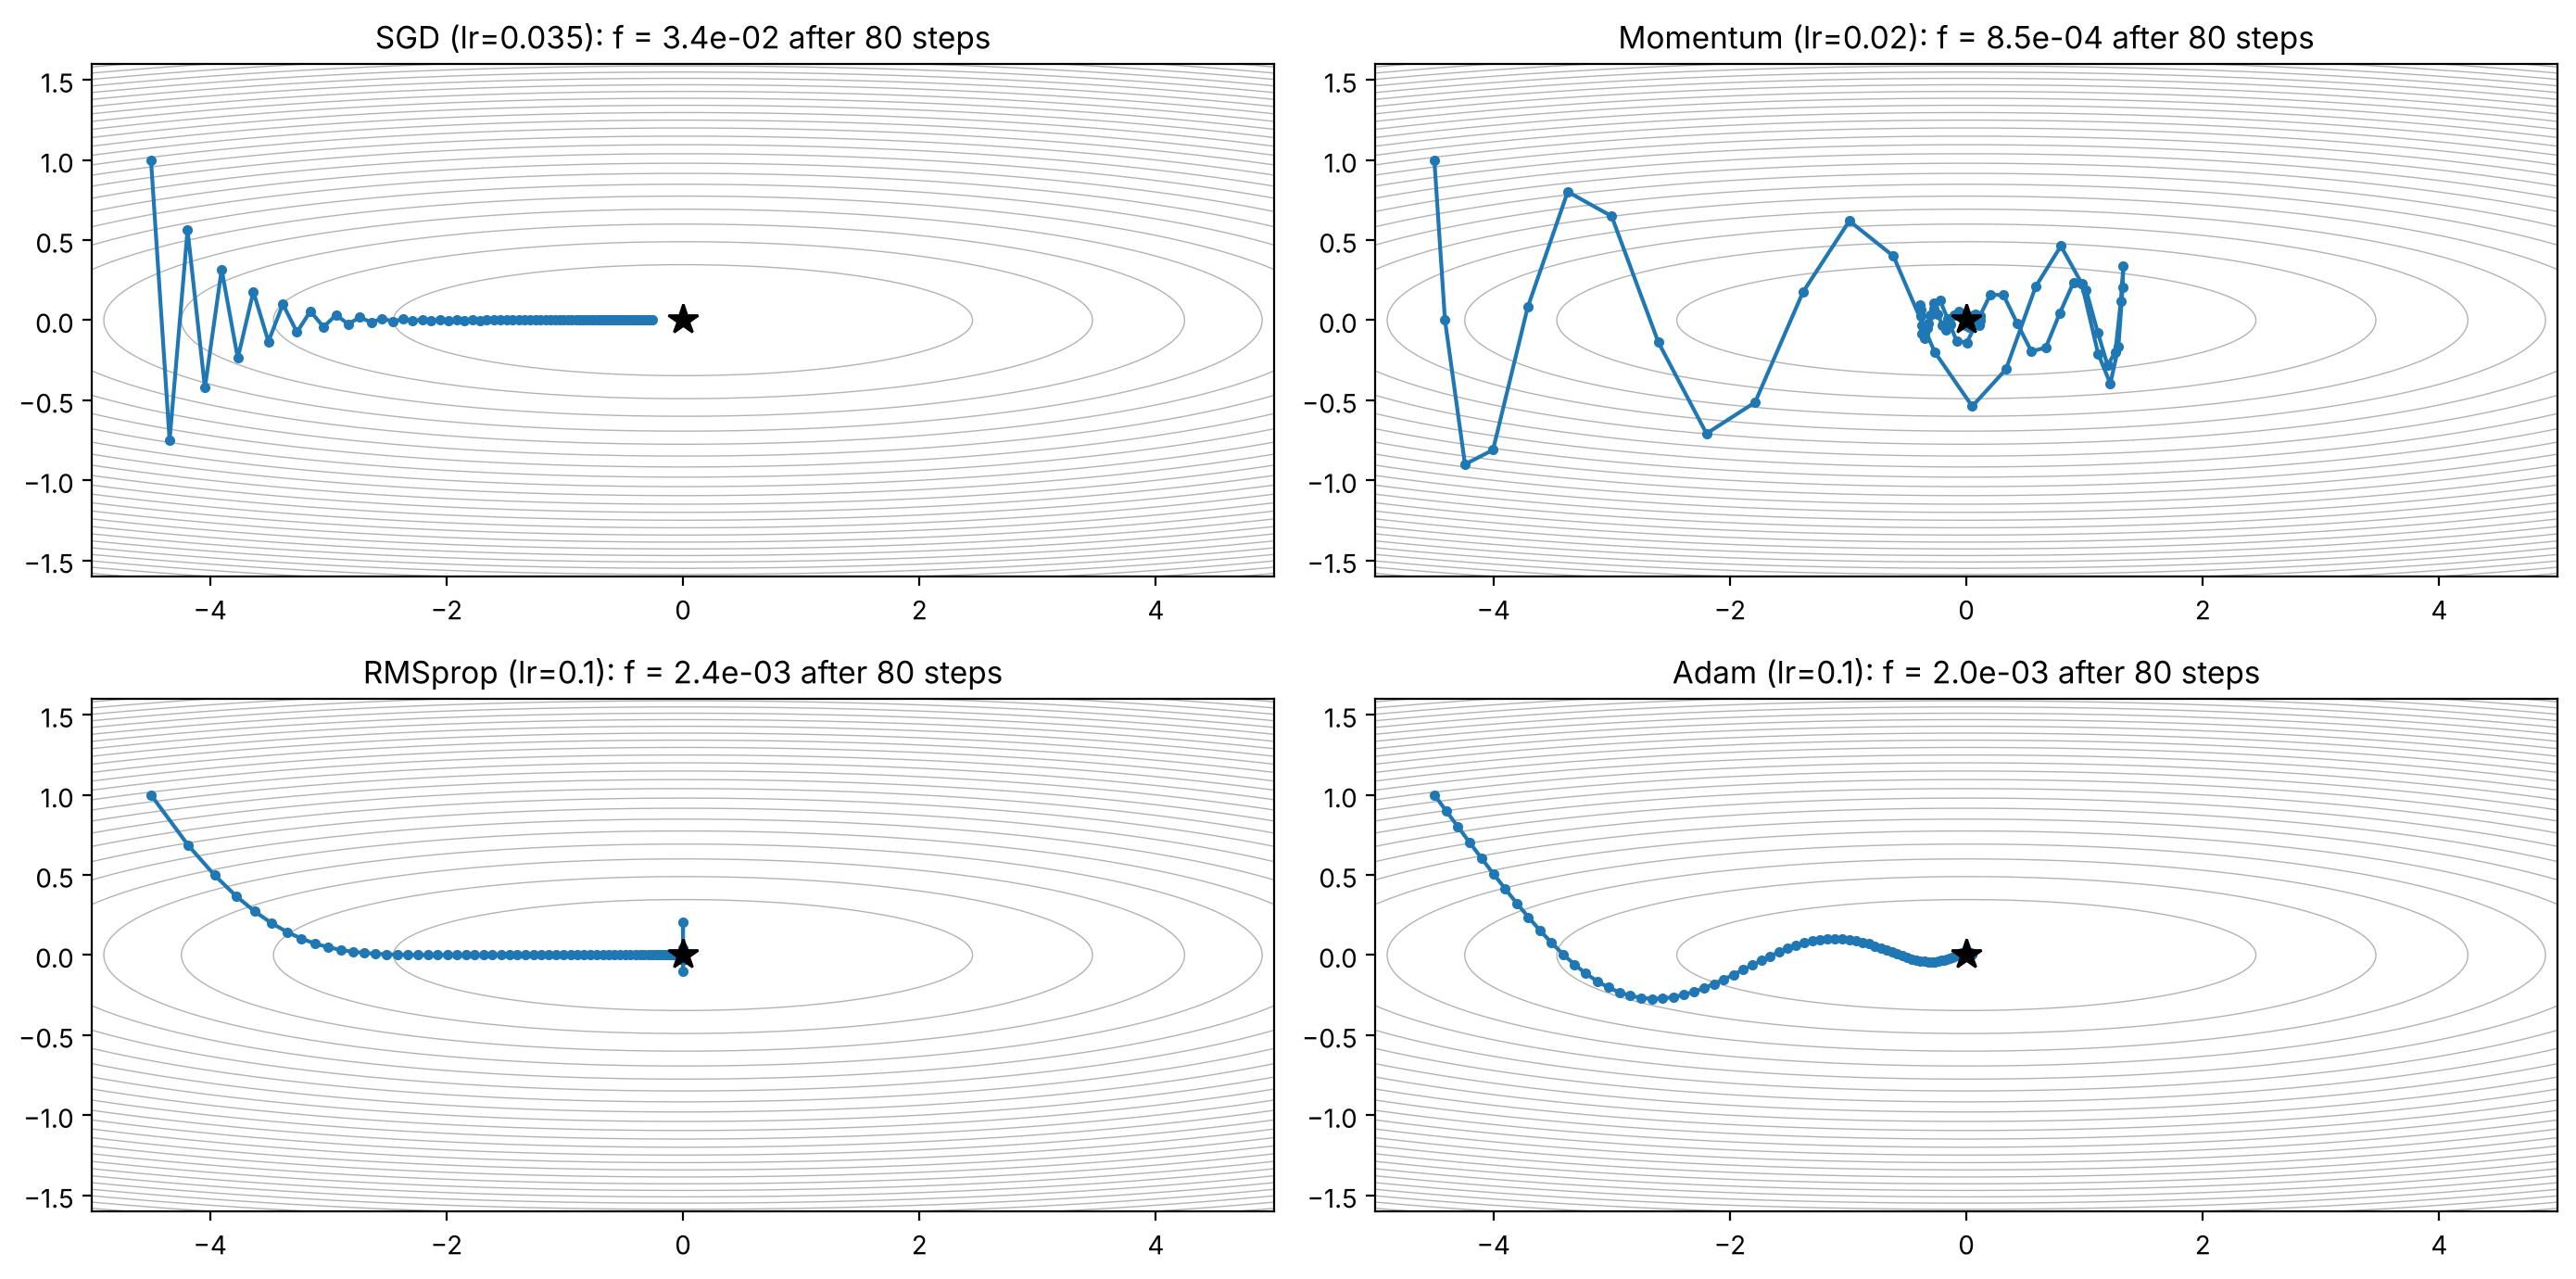

In [2]:
A = np.array([1.0, 50.0])
f = lambda th: 0.5 * np.sum(A * th ** 2)
grad = lambda th: A * th
start = np.array([-4.5, 1.0])


def run(update, steps=80):
    th, state, path = start.copy(), {}, [start.copy()]
    for t in range(1, steps + 1):
        th = update(th, grad(th), state, t)
        path.append(th.copy())
    return np.array(path)


def sgd(lr):
    return lambda th, g, s, t: th - lr * g


def momentum(lr, beta=0.9):
    def step(th, g, s, t):
        s['v'] = beta * s.get('v', 0) + g          # velocity: running sum of past gradients
        return th - lr * s['v']
    return step


def rmsprop(lr, beta=0.9, eps=1e-8):
    def step(th, g, s, t):
        s['sq'] = beta * s.get('sq', 0) + (1 - beta) * g ** 2   # running mean of squared gradients
        return th - lr * g / (np.sqrt(s['sq']) + eps)
    return step


def adam(lr, b1=0.9, b2=0.999, eps=1e-8):
    def step(th, g, s, t):
        s['m'] = b1 * s.get('m', 0) + (1 - b1) * g               # 1st moment (momentum)
        s['v'] = b2 * s.get('v', 0) + (1 - b2) * g ** 2          # 2nd moment (RMSprop)
        m_hat = s['m'] / (1 - b1 ** t)                           # bias correction
        v_hat = s['v'] / (1 - b2 ** t)
        return th - lr * m_hat / (np.sqrt(v_hat) + eps)
    return step


runs = {
    'SGD (lr=0.035)': run(sgd(0.035)),
    'Momentum (lr=0.02)': run(momentum(0.02)),
    'RMSprop (lr=0.1)': run(rmsprop(0.1)),
    'Adam (lr=0.1)': run(adam(0.1)),
}

g1, g2 = np.meshgrid(np.linspace(-5, 5, 300), np.linspace(-1.6, 1.6, 300))
Z = 0.5 * (A[0] * g1 ** 2 + A[1] * g2 ** 2)
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for ax, (name, path) in zip(axes.flat, runs.items()):
    ax.contour(g1, g2, Z, levels=25, colors='gray', linewidths=0.5, alpha=0.6)
    ax.plot(path[:, 0], path[:, 1], 'o-', ms=3, lw=1.5)
    ax.plot(0, 0, 'k*', ms=12)
    ax.set_title(f'{name}: f = {f(path[-1]):.1e} after 80 steps')
plt.tight_layout(); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تحلیل

**SGD:** بعد از ۸۰ گام هنوز فاصله زیادی تا کمینه دارد. نرخ یادگیری را نمی‌توان بزرگ گرفت، چون در جهت پرشیب ($\theta_2$) واگرا می‌شود (برای این تابع باید $\eta < 2/50 = 0.04$ باشد). با همین نرخ کوچک، پیشرفت در جهت کم‌شیب ($\theta_1$) بسیار کند است.

**Momentum:** یک «سرعت» از میانگین گرادیان‌های قبلی نگه می‌دارد:

$$\mathbf{v}_t = \beta\,\mathbf{v}_{t-1} + \nabla\mathcal{L}(\theta_t), \qquad \theta_{t+1} = \theta_t - \eta\,\mathbf{v}_t$$

در جهتی که گرادیان ثابت است سرعت جمع می‌شود و حرکت تند می‌شود؛ در جهتی که گرادیان مدام علامت عوض می‌کند، نوسان‌ها همدیگر را خنثی می‌کنند. مثل توپی که از سراشیبی پایین می‌غلتد. مقدار رایج $\beta = 0.9$ است. در نمودار بالا Momentum از کمینه رد می‌شود و برمی‌گردد (Overshooting)، اما بعد از ۸۰ گام مقدار تابع را حدود ۴۰ برابر کمتر از SGD کرده است.

**RMSprop:** برای هر پارامتر، گرادیان را بر ریشه میانگین مربعات گرادیان‌های اخیر تقسیم می‌کند:

$$\mathbf{s}_t = \beta\,\mathbf{s}_{t-1} + (1-\beta)\,\mathbf{g}_t^2, \qquad \theta_{t+1} = \theta_t - \eta\,\frac{\mathbf{g}_t}{\sqrt{\mathbf{s}_t} + \epsilon}$$

نتیجه یک **نرخ یادگیری تطبیقی (Adaptive)** برای هر پارامتر است: پارامتری با گرادیان‌های بزرگ قدم کوچک‌تر و پارامتری با گرادیان‌های کوچک قدم بزرگ‌تر برمی‌دارد.

**Adam** (Kingma & Ba, 2015) هر دو ایده را ترکیب می‌کند: Momentum (گشتاور اول $\mathbf{m}$) و RMSprop (گشتاور دوم $\mathbf{v}$):

$$\mathbf{m}_t = \beta_1\mathbf{m}_{t-1} + (1-\beta_1)\mathbf{g}_t,\qquad \mathbf{v}_t = \beta_2\mathbf{v}_{t-1} + (1-\beta_2)\mathbf{g}_t^2$$

$$\hat{\mathbf{m}}_t = \frac{\mathbf{m}_t}{1-\beta_1^t},\qquad \hat{\mathbf{v}}_t = \frac{\mathbf{v}_t}{1-\beta_2^t},\qquad \theta_{t+1} = \theta_t - \eta\,\frac{\hat{\mathbf{m}}_t}{\sqrt{\hat{\mathbf{v}}_t}+\epsilon}$$

چون $\mathbf{m}$ و $\mathbf{v}$ از صفر شروع می‌شوند، در گام‌های اول به سمت صفر متمایل‌اند؛ **تصحیح بایاس (Bias Correction)** این اثر را جبران می‌کند. مقادیر پیش‌فرض $\beta_1=0.9$، $\beta_2=0.999$ و $\eta = 10^{-3}$ در اغلب مسائل خوب کار می‌کنند.

## ۳. مقایسه بهینه‌سازها روی Fashion-MNIST

حالا همان MLP جلسه قبل را با بهینه‌سازهای مختلف PyTorch آموزش می‌دهیم. داده و توابع آموزش همان جلسه ۴ هستند (تابع `fit` فقط حلقه Epoch را در خود دارد):

</div>

In [3]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.2860,), (0.3530,))])
full_train = datasets.FashionMNIST(root='data', train=True, download=True, transform=transform)
test_set = datasets.FashionMNIST(root='data', train=False, download=True, transform=transform)
train_set, val_set = random_split(full_train, [50_000, 10_000], generator=torch.Generator().manual_seed(42))
CLASSES = full_train.classes

train_loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=2)
val_loader = DataLoader(val_set, batch_size=512, num_workers=2)
test_loader = DataLoader(test_set, batch_size=512, num_workers=2)
print('train / val / test:', len(train_set), len(val_set), len(test_set))

train / val / test: 50000 10000 10000


In [4]:
def train_one_epoch(model, loader, criterion, optimizer, device, scheduler=None):
    """One pass over the training data. `scheduler` is stepped after every batch if given."""
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        loss = criterion(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if scheduler is not None:
            scheduler.step()
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        total_loss += criterion(logits, y).item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def fit(model, train_loader, val_loader, optimizer, epochs, device, scheduler=None, verbose=True):
    """Train for `epochs` epochs and return the history of losses and accuracies."""
    criterion = nn.CrossEntropyLoss()
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    for epoch in range(1, epochs + 1):
        tr = train_one_epoch(model, train_loader, criterion, optimizer, device, scheduler)
        va = evaluate(model, val_loader, criterion, device)
        for k, v in zip(history, (*tr, *va)):
            history[k].append(v)
        if verbose:
            print(f'epoch {epoch:2d} | train loss {tr[0]:.4f} acc {tr[1]:.4f} | val loss {va[0]:.4f} acc {va[1]:.4f}')
    return history

In [5]:
def make_mlp():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 256), nn.ReLU(),
        nn.Linear(256, 128), nn.ReLU(),
        nn.Linear(128, 10),
    )


EPOCHS = 8
optimizers = {
    'SGD':          lambda p: torch.optim.SGD(p, lr=0.05),
    'SGD+Momentum': lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9),
    'RMSprop':      lambda p: torch.optim.RMSprop(p, lr=1e-3),
    'Adam':         lambda p: torch.optim.Adam(p, lr=1e-3),
    'AdamW':        lambda p: torch.optim.AdamW(p, lr=1e-3, weight_decay=1e-2),
}

results = {}
for name, make_opt in optimizers.items():
    torch.manual_seed(0)                       # identical initial weights for a fair comparison
    model = make_mlp().to(device)
    print(f'--- {name}')
    results[name] = fit(model, train_loader, val_loader, make_opt(model.parameters()), EPOCHS, device, verbose=False)
    print(f"final val acc {results[name]['val_acc'][-1]:.4f} | best val loss {min(results[name]['val_loss']):.4f}")

--- SGD


final val acc 0.8715 | best val loss 0.3538
--- SGD+Momentum


final val acc 0.8882 | best val loss 0.3322
--- RMSprop


final val acc 0.8731 | best val loss 0.3175
--- Adam


final val acc 0.8948 | best val loss 0.3096
--- AdamW


final val acc 0.8955 | best val loss 0.3047


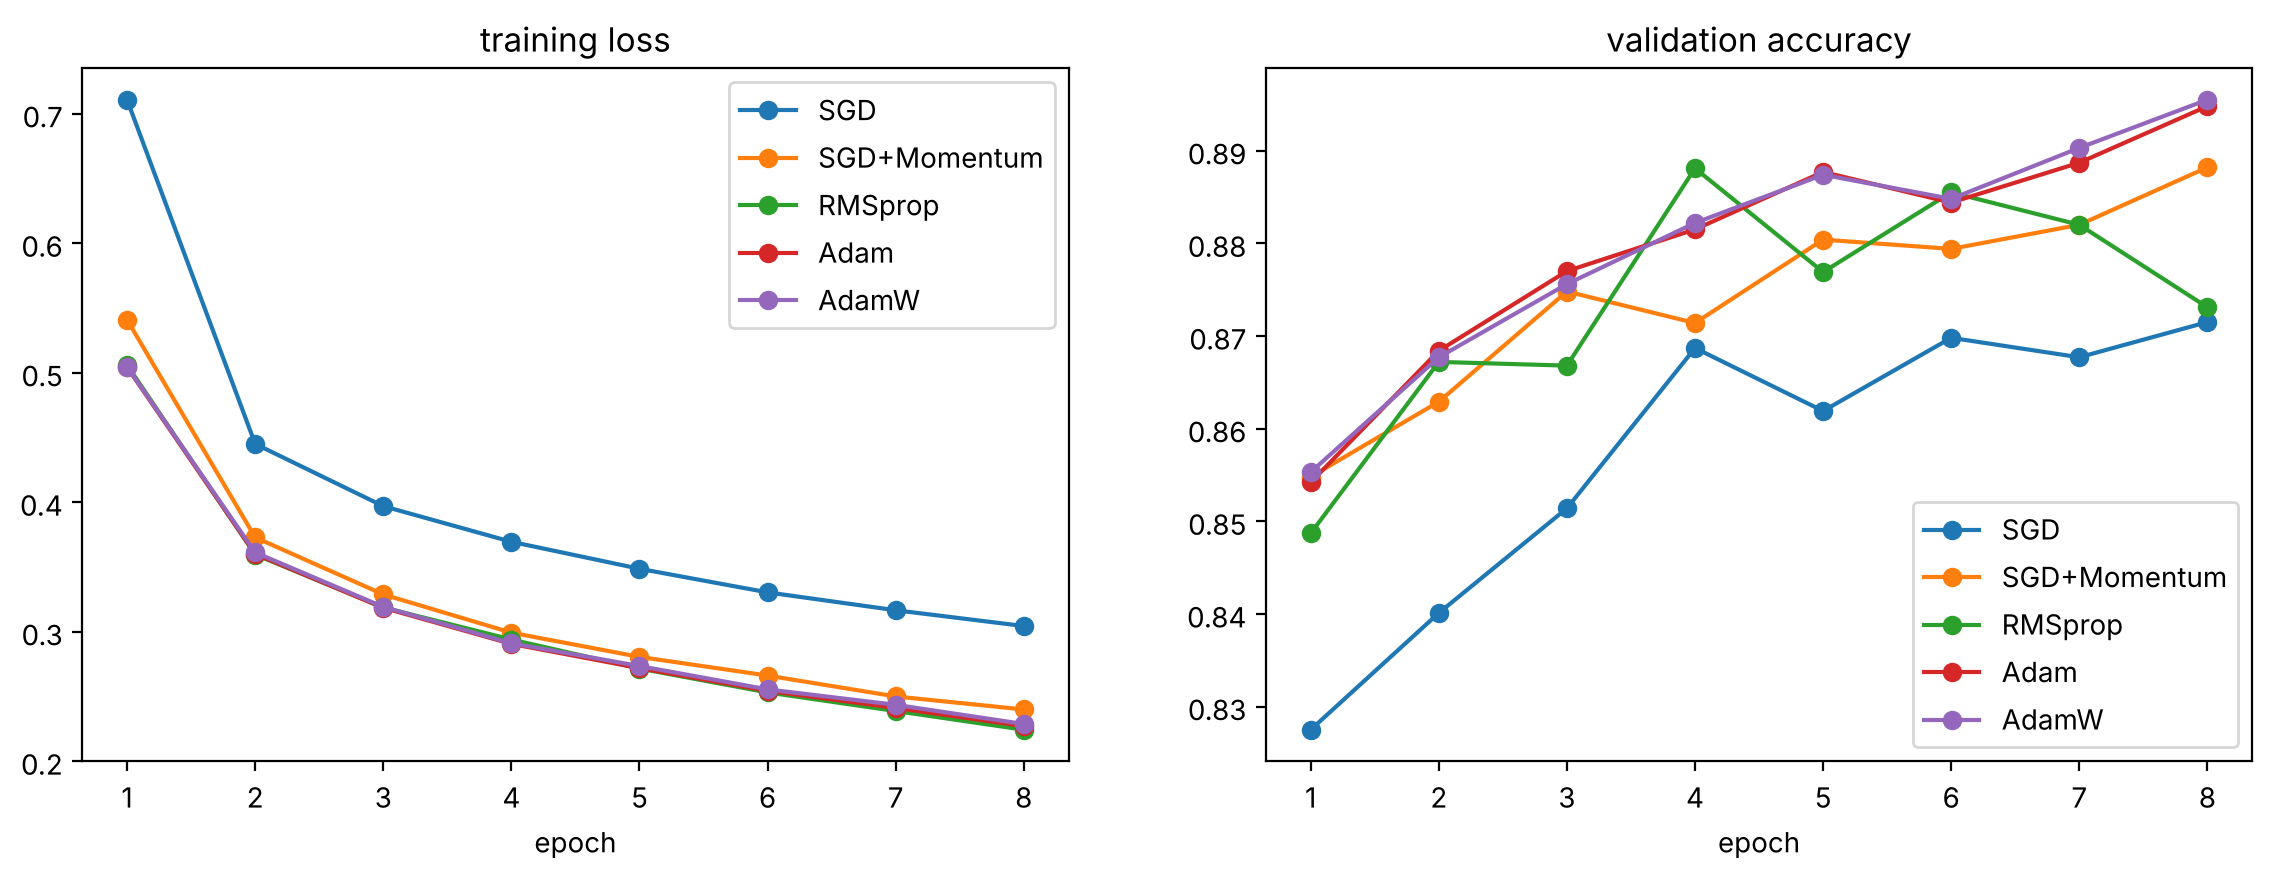

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, h in results.items():
    axes[0].plot(range(1, EPOCHS + 1), h['train_loss'], 'o-', label=name)
    axes[1].plot(range(1, EPOCHS + 1), h['val_acc'], 'o-', label=name)
axes[0].set_title('training loss'); axes[1].set_title('validation accuracy')
for ax in axes:
    ax.set_xlabel('epoch'); ax.legend()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**نکات:**

- SGD ساده کندتر از همه همگرا می‌شود و افزودن Momentum تفاوت بزرگی ایجاد می‌کند.
- Adam و RMSprop بدون تنظیم زیاد، سریع همگرا می‌شوند. به همین دلیل **Adam انتخاب پیش‌فرض خوبی برای شروع** است.
- در بسیاری از مسائل بینایی، SGD+Momentum با زمان‌بندی مناسب نرخ یادگیری در نهایت به تعمیم (Generalization) کمی بهتر می‌رسد؛ برای Transformerها تقریباً همیشه از AdamW استفاده می‌شود.

### AdamW: جداسازی Weight Decay

**Weight Decay** (جریمه L2 روی وزن‌ها) در جلسه ۶ به‌تفصیل بررسی می‌شود. نکته اینجاست: در Adam معمولی، جمله جریمه به گرادیان اضافه می‌شود و سپس بر $\sqrt{\hat{\mathbf{v}}}$ تقسیم می‌شود؛ پس اثر آن برای هر پارامتر متفاوت و ناخواسته است. **AdamW** (Loshchilov & Hutter, 2019) کاهش وزن را مستقیم و جدا از گرادیان اعمال می‌کند:

$$\theta_{t+1} = \theta_t - \eta\left(\frac{\hat{\mathbf{m}}_t}{\sqrt{\hat{\mathbf{v}}_t}+\epsilon} + \lambda\,\theta_t\right)$$

AdamW بهینه‌ساز استاندارد آموزش BERT، GPT و اغلب مدل‌های مدرن است.

## ۴. نرخ یادگیری: مهم‌ترین ابرپارامتر

### آزمون بازه نرخ یادگیری (LR Range Test)

روشی ساده و کاربردی (Smith, 2017) برای پیدا کردن نرخ یادگیری مناسب: آموزش را با نرخ یادگیری بسیار کوچک شروع می‌کنیم و در هر Batch آن را به‌صورت نمایی بزرگ می‌کنیم تا Loss منفجر شود. نرخ مناسب معمولاً **حدود یک دهم** نقطه‌ای است که Loss در آن کمینه است، یعنی جایی که Loss هنوز با شیب تند در حال کاهش است.

</div>

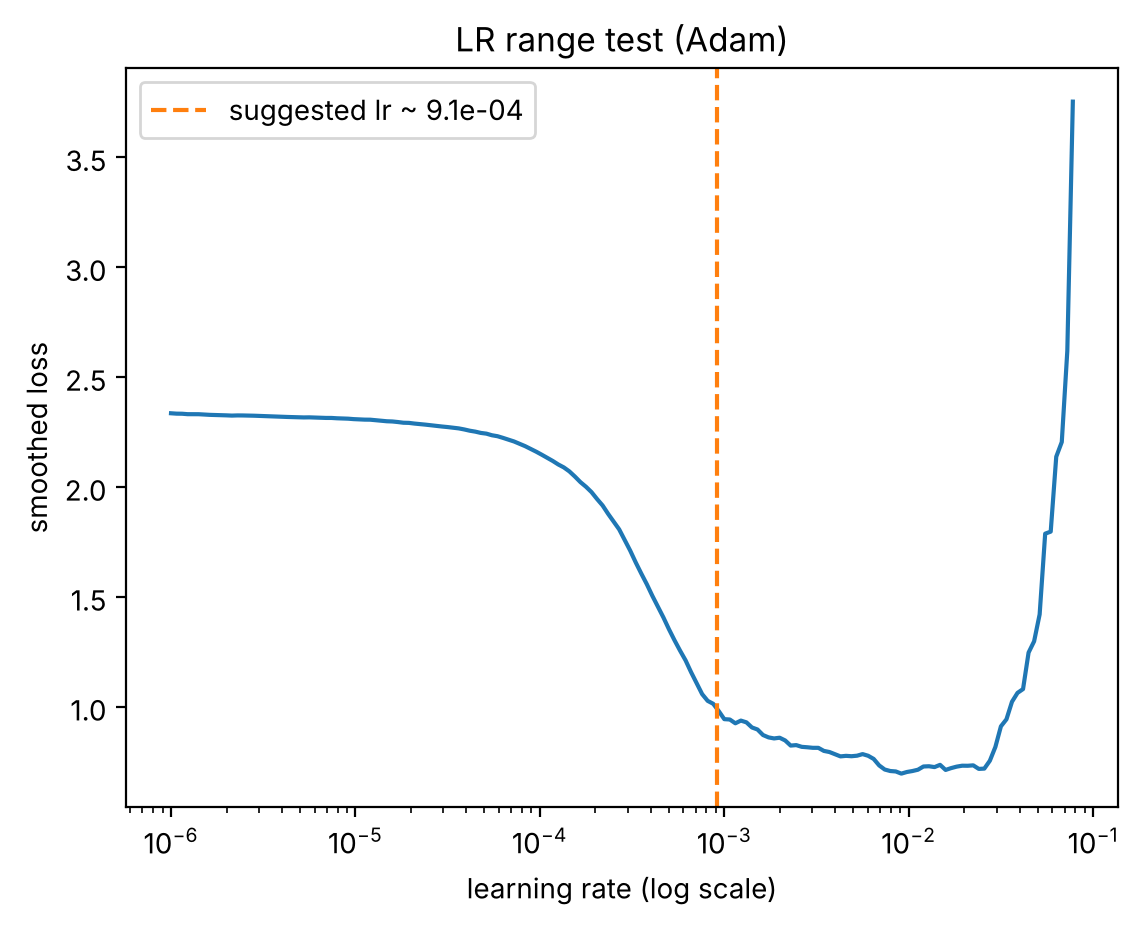

In [7]:
def lr_range_test(model, loader, make_optimizer, lr_min=1e-6, lr_max=1, steps=200):
    criterion = nn.CrossEntropyLoss()
    optimizer = make_optimizer(model.parameters(), lr_min)
    gamma = (lr_max / lr_min) ** (1 / steps)
    lrs, losses, smooth = [], [], None
    model.train()
    data_iter = iter(loader)
    for step in range(steps):
        try:
            X, y = next(data_iter)
        except StopIteration:
            data_iter = iter(loader)
            X, y = next(data_iter)
        X, y = X.to(device), y.to(device)
        loss = criterion(model(X), y)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        smooth = loss.item() if smooth is None else 0.9 * smooth + 0.1 * loss.item()   # exponential smoothing
        lrs.append(optimizer.param_groups[0]['lr']); losses.append(smooth)
        if smooth > 4 * min(losses):                      # loss exploded: stop
            break
        for g in optimizer.param_groups:
            g['lr'] *= gamma
    return np.array(lrs), np.array(losses)


torch.manual_seed(0)
lrs, losses = lr_range_test(make_mlp().to(device), train_loader, lambda p, lr: torch.optim.Adam(p, lr=lr))
best = lrs[np.argmin(losses)]
plt.semilogx(lrs, losses)
plt.axvline(best / 10, color='C1', ls='--', label=f'suggested lr ~ {best / 10:.1e}')
plt.xlabel('learning rate (log scale)'); plt.ylabel('smoothed loss'); plt.legend(); plt.title('LR range test (Adam)')
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### زمان‌بندی نرخ یادگیری (Learning-Rate Scheduling)

نرخ یادگیری ثابت معمولاً بهینه نیست: در ابتدای آموزش قدم‌های بزرگ برای پیشرفت سریع مفیدند و در پایان قدم‌های کوچک برای نشستن دقیق در کمینه. ماژول `torch.optim.lr_scheduler` زمان‌بندهای آماده دارد:

| زمان‌بند | رفتار | کاربرد رایج |
|---|---|---|
| `StepLR` | هر چند Epoch نرخ را در عددی مثل $0.1$ ضرب می‌کند | روش کلاسیک برای CNNها |
| `CosineAnnealingLR` | کاهش نرم به شکل نیم‌دوره کسینوس | بسیار رایج در بینایی ماشین |
| `OneCycleLR` | ابتدا افزایش (Warmup) و سپس کاهش کسینوسی | همگرایی سریع با تعداد Epoch کم |
| Linear Warmup + Decay | افزایش خطی و سپس کاهش خطی یا کسینوسی | استاندارد آموزش Transformerها |

**Warmup** در ابتدای آموزش، وقتی وزن‌ها تصادفی و تخمین‌های Adam هنوز ناپایدارند، از قدم‌های بزرگ و مخرب جلوگیری می‌کند. شکل این زمان‌بندها را رسم می‌کنیم:

</div>

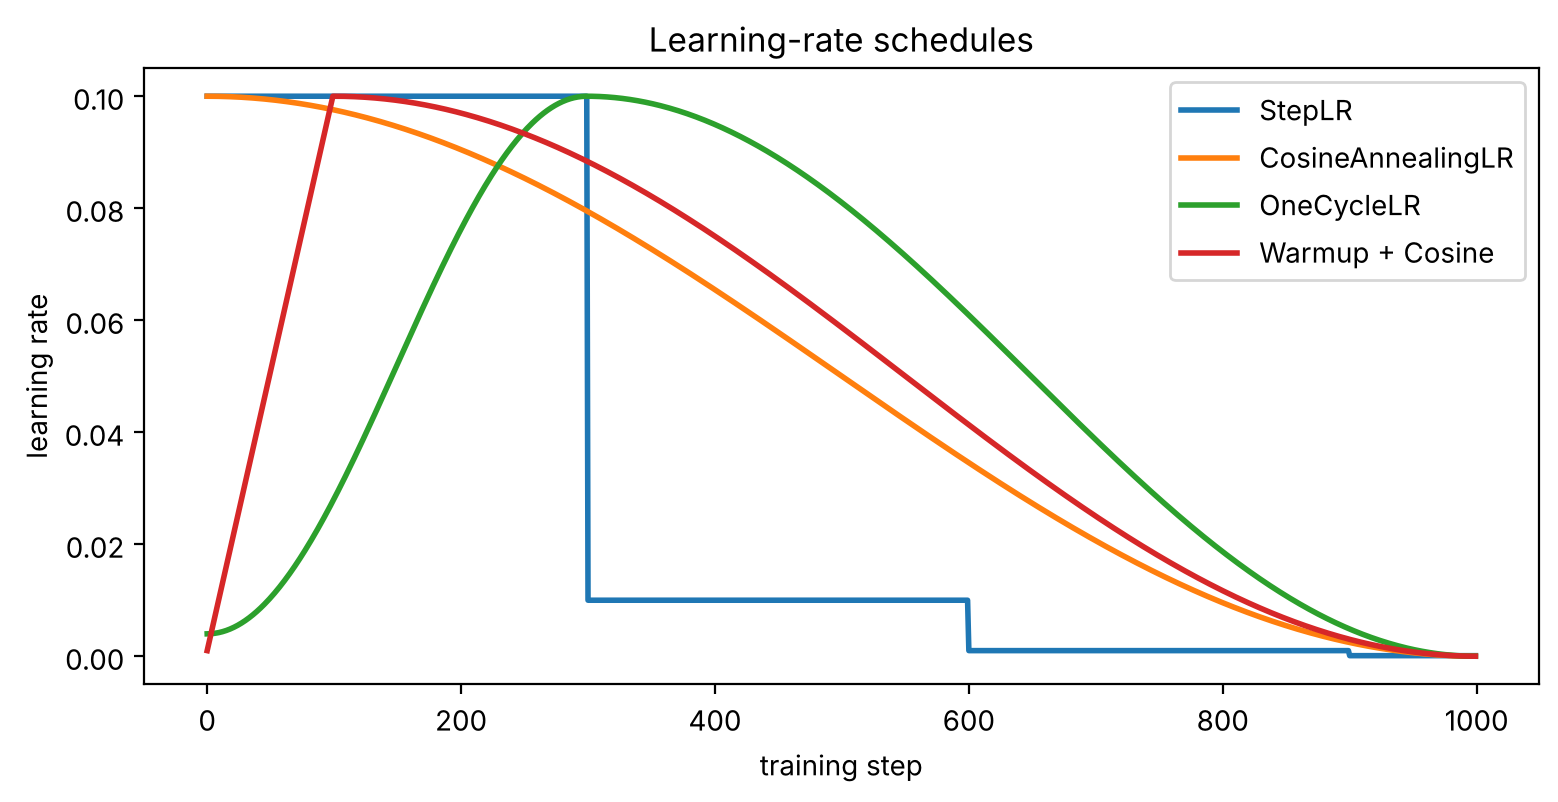

In [8]:
def schedule_curve(make_scheduler, total_steps=1000, base_lr=0.1):
    opt = torch.optim.SGD([torch.zeros(1, requires_grad=True)], lr=base_lr)
    sched = make_scheduler(opt)
    lrs = []
    for _ in range(total_steps):
        lrs.append(opt.param_groups[0]['lr'])
        opt.step(); sched.step()
    return lrs


def warmup_cosine(opt, warmup=100, total=1000):
    def factor(step):
        if step < warmup:
            return (step + 1) / warmup
        progress = (step - warmup) / (total - warmup)
        return 0.5 * (1 + math.cos(math.pi * progress))
    return torch.optim.lr_scheduler.LambdaLR(opt, factor)


schedules = {
    'StepLR': lambda o: torch.optim.lr_scheduler.StepLR(o, step_size=300, gamma=0.1),
    'CosineAnnealingLR': lambda o: torch.optim.lr_scheduler.CosineAnnealingLR(o, T_max=1000),
    'OneCycleLR': lambda o: torch.optim.lr_scheduler.OneCycleLR(o, max_lr=0.1, total_steps=1000),
    'Warmup + Cosine': warmup_cosine,
}
plt.figure(figsize=(9, 4))
for name, make in schedules.items():
    plt.plot(schedule_curve(make), label=name, lw=2)
plt.xlabel('training step'); plt.ylabel('learning rate'); plt.legend(); plt.title('Learning-rate schedules')
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**نکته مهم در استفاده:** بعضی زمان‌بندها (مثل `OneCycleLR`) بر حسب **گام** (Batch) تعریف می‌شوند و باید بعد از هر `optimizer.step()` صدا زده شوند؛ بعضی دیگر (مثل `StepLR` با `step_size` بر حسب Epoch) در پایان هر Epoch. تابع `train_one_epoch` ما آرگومان اختیاری `scheduler` دارد که بعد از هر Batch آن را جلو می‌برد.

مدل را با AdamW و OneCycleLR آموزش می‌دهیم و با AdamW با نرخ ثابت مقایسه می‌کنیم:

</div>

epoch  1 | train loss 0.7224 acc 0.7630 | val loss 0.4726 acc 0.8285


epoch  2 | train loss 0.4201 acc 0.8446 | val loss 0.4250 acc 0.8476


epoch  3 | train loss 0.3675 acc 0.8637 | val loss 0.3592 acc 0.8710


epoch  4 | train loss 0.3191 acc 0.8810 | val loss 0.3258 acc 0.8827


epoch  5 | train loss 0.2822 acc 0.8939 | val loss 0.3122 acc 0.8867


epoch  6 | train loss 0.2428 acc 0.9080 | val loss 0.3041 acc 0.8897


epoch  7 | train loss 0.2049 acc 0.9220 | val loss 0.2866 acc 0.8947


epoch  8 | train loss 0.1812 acc 0.9317 | val loss 0.2800 acc 0.8982


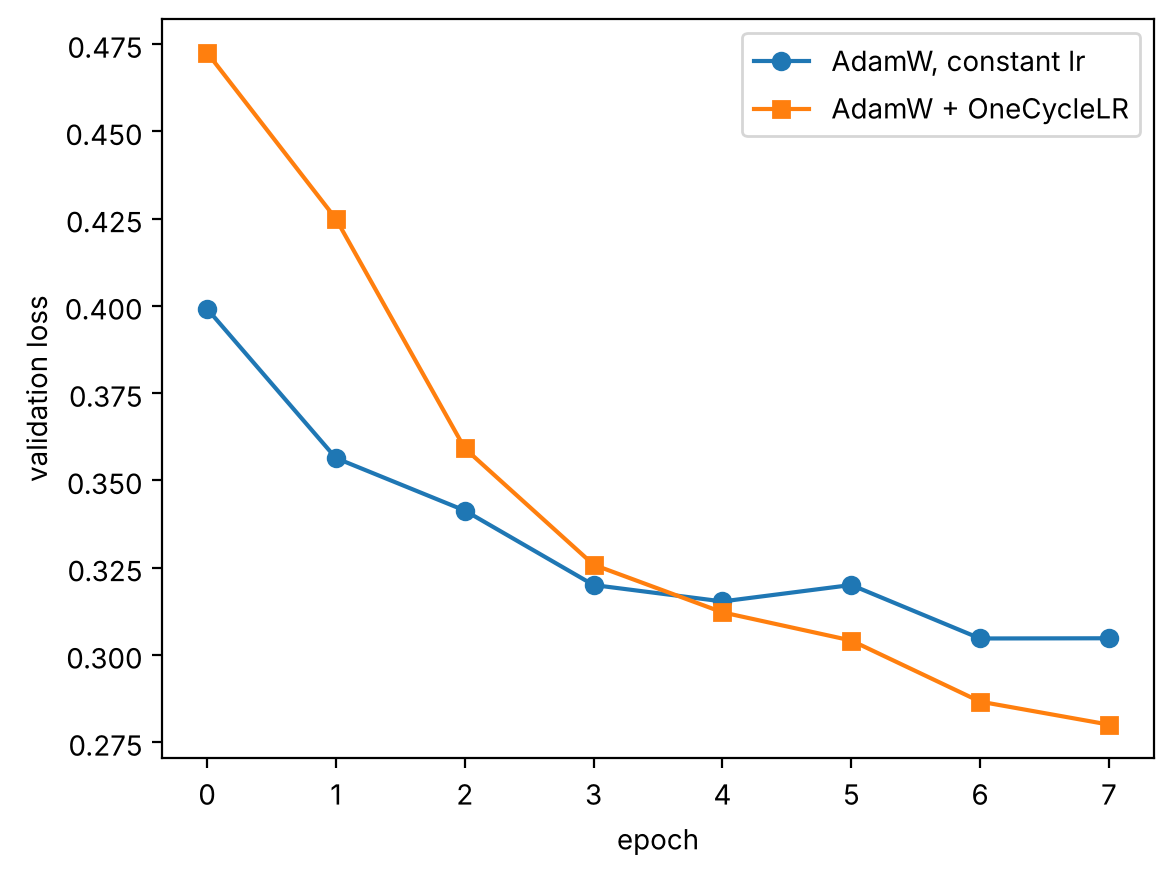

In [9]:
torch.manual_seed(0)
model = make_mlp().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=3e-3, epochs=EPOCHS, steps_per_epoch=len(train_loader))
hist_onecycle = fit(model, train_loader, val_loader, optimizer, EPOCHS, device, scheduler=scheduler)

plt.plot(results['AdamW']['val_loss'], 'o-', label='AdamW, constant lr')
plt.plot(hist_onecycle['val_loss'], 's-', label='AdamW + OneCycleLR')
plt.xlabel('epoch'); plt.ylabel('validation loss'); plt.legend(); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۵. مقداردهی اولیه وزن‌ها (Weight Initialization)

وزن‌های اولیه تعیین می‌کنند سیگنال در Forward و گرادیان در Backward چطور از لایه‌ها عبور کنند.

- **همه صفر (یا همه برابر):** همه نورون‌های یک لایه دقیقاً یک خروجی و یک گرادیان دارند و هیچ‌وقت متفاوت نمی‌شوند (**مشکل تقارن یا Symmetry**). مقداردهی باید تصادفی باشد.
- **خیلی کوچک:** فعال‌سازی‌ها در لایه‌های عمیق به صفر میل می‌کنند (و گرادیان‌ها هم).
- **خیلی بزرگ:** فعال‌سازی‌ها منفجر می‌شوند یا توابعی مثل Tanh اشباع می‌شوند.

ایده اصلی: واریانس خروجی هر لایه برابر واریانس ورودی آن بماند. برای لایه‌ای با $n_{\text{in}}$ ورودی:

| روش | واریانس وزن‌ها | مناسب برای |
|---|---|---|
| Xavier / Glorot (2010) | $\dfrac{2}{n_{\text{in}} + n_{\text{out}}}$ | Tanh و Sigmoid |
| He / Kaiming (2015) | $\dfrac{2}{n_{\text{in}}}$ | ReLU و انواع آن |

ضریب ۲ در He به این دلیل است که ReLU نیمی از ورودی‌ها را صفر می‌کند. در آزمایش زیر یک شبکه ۱۰ لایه ReLU می‌سازیم و انحراف معیار فعال‌سازی‌ها را در هر لایه برای سه روش مقداردهی رسم می‌کنیم:

</div>

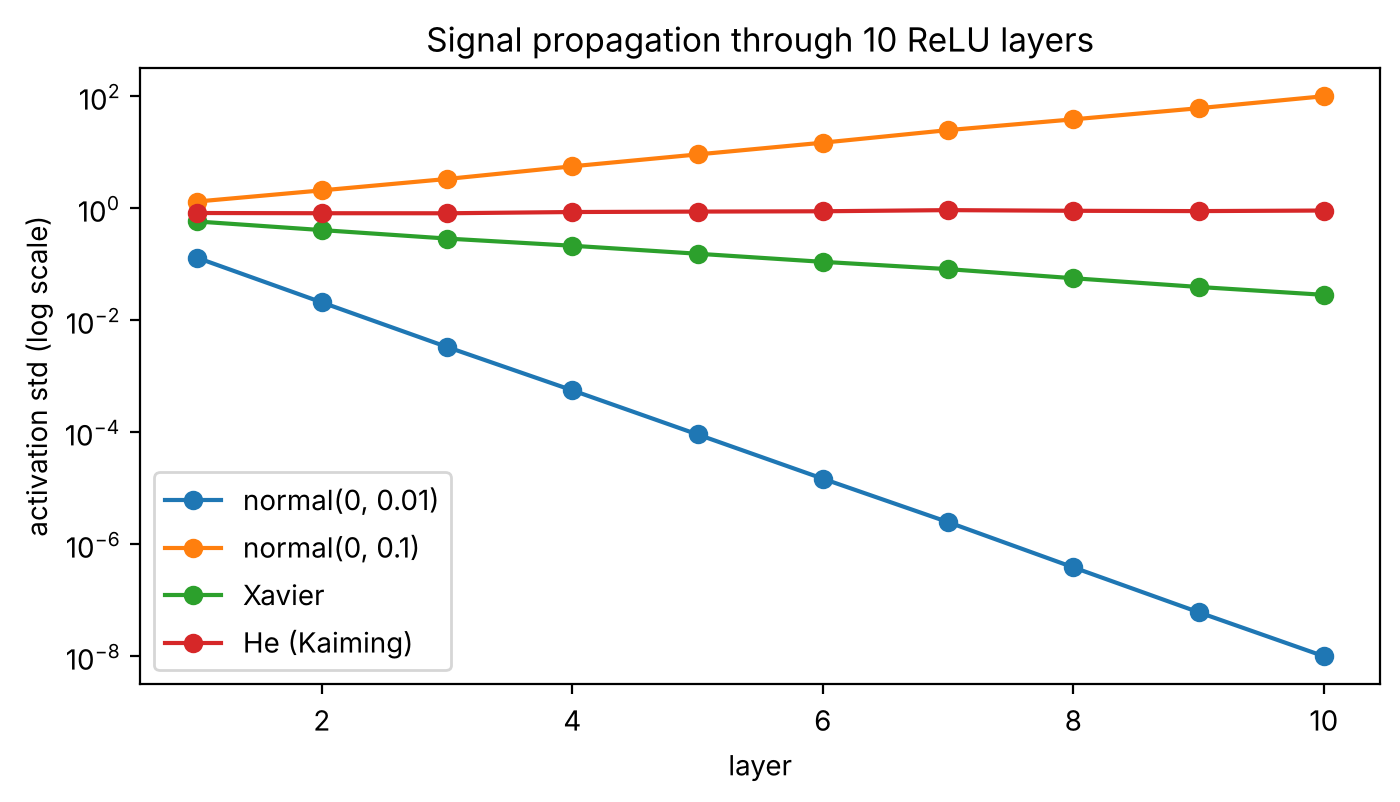

In [10]:
def activation_stds(init_fn, n_layers=10, width=512):
    torch.manual_seed(0)
    layers = [nn.Linear(width, width) for _ in range(n_layers)]
    for layer in layers:
        init_fn(layer.weight)
        nn.init.zeros_(layer.bias)
    h = torch.randn(1000, width)
    stds = []
    with torch.no_grad():
        for layer in layers:
            h = torch.relu(layer(h))
            stds.append(h.std().item())
    return stds


inits = {
    'normal(0, 0.01)': lambda w: nn.init.normal_(w, std=0.01),
    'normal(0, 0.1)': lambda w: nn.init.normal_(w, std=0.1),
    'Xavier': nn.init.xavier_normal_,
    'He (Kaiming)': lambda w: nn.init.kaiming_normal_(w, nonlinearity='relu'),
}
plt.figure(figsize=(8, 4))
for name, fn in inits.items():
    plt.semilogy(range(1, 11), activation_stds(fn), 'o-', label=name)
plt.xlabel('layer'); plt.ylabel('activation std (log scale)'); plt.legend()
plt.title('Signal propagation through 10 ReLU layers'); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با He، انحراف معیار فعال‌سازی‌ها در همه لایه‌ها تقریباً ثابت می‌ماند؛ با مقداردهی کوچک سیگنال به سرعت محو و با مقداردهی بزرگ منفجر می‌شود. Xavier برای ReLU کمی کوچک است و سیگنال آرام‌آرام ضعیف می‌شود.

**در عمل:** لایه‌های `nn.Linear` و `nn.Conv2d` در PyTorch به‌طور پیش‌فرض با نوعی مقداردهی Kaiming-Uniform مقداردهی می‌شوند که برای اغلب مسائل مناسب است. اگر بخواهید مقداردهی را خودتان کنترل کنید:

</div>

In [11]:
def init_weights(module):
    if isinstance(module, (nn.Linear, nn.Conv2d)):
        nn.init.kaiming_normal_(module.weight, nonlinearity='relu')
        nn.init.zeros_(module.bias)


model = make_mlp()
model.apply(init_weights)            # .apply visits every sub-module recursively
print('std of first-layer weights:', model[1].weight.std().item(), ' expected ~', math.sqrt(2 / 784))

std of first-layer weights: 0.050507549196481705  expected ~ 0.050507627227610534


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## جمع‌بندی و توصیه‌های عملی

- **Momentum** نوسان را کم و حرکت در جهت‌های ثابت را تند می‌کند. **RMSprop** نرخ یادگیری هر پارامتر را تطبیقی می‌کند. **Adam** هر دو را با تصحیح بایاس ترکیب می‌کند.
- برای شروع: **AdamW با نرخ یادگیری حدود $10^{-3}$**. برای CNNها، SGD با Momentum برابر $0.9$ و زمان‌بند کسینوسی هم گزینه بسیار خوبی است.
- نرخ یادگیری مهم‌ترین ابرپارامتر است؛ با LR Range Test آن را پیدا کنید.
- از زمان‌بند استفاده کنید: Cosine یا OneCycle برای CNN، Warmup + Cosine/Linear برای Transformer.
- مقداردهی اولیه He برای ReLU و Xavier برای Tanh؛ پیش‌فرض PyTorch در اغلب موارد کافی است.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. تابع Rosenbrock، یعنی $f(x, y) = (1-x)^2 + 100(y-x^2)^2$، را با چهار بهینه‌ساز پیاده‌سازی‌شده در بخش ۲ کمینه کنید (از نقطه $(-1.5, 2)$ شروع کنید) و مسیرها را رسم کنید. کدام زودتر به $(1, 1)$ می‌رسد؟

۲. **Nesterov Momentum** را به فهرست بهینه‌سازهای بخش ۲ اضافه کنید (در PyTorch: `SGD(..., momentum=0.9, nesterov=True)`) و تفاوتش را با Momentum معمولی توضیح دهید.

۳. Adam را با نرخ‌های یادگیری $10^{-4}$، $10^{-3}$ و $10^{-2}$ روی Fashion-MNIST آموزش دهید. نتایج را با پیشنهاد LR Range Test مقایسه کنید.

۴. در آزمایش مقداردهی اولیه، تابع فعال‌سازی را به Tanh تغییر دهید (`torch.tanh`). این بار کدام روش مقداردهی بهتر عمل می‌کند؟

۵. با `StepLR` (هر ۳ Epoch ضرب در $0.1$) و SGD+Momentum مدل را آموزش دهید. دقت کنید `scheduler.step()` باید در پایان هر Epoch صدا زده شود، نه بعد از هر Batch.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** تابع Rosenbrock، یعنی $f(x, y) = (1-x)^2 + 100(y-x^2)^2$، را با چهار بهینه‌ساز پیاده‌سازی‌شده در بخش ۲ کمینه کنید (از نقطه $(-1.5, 2)$ شروع کنید) و مسیرها را رسم کنید. کدام زودتر به $(1, 1)$ می‌رسد؟

</div>

In [12]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** **Nesterov Momentum** را به فهرست بهینه‌سازهای بخش ۲ اضافه کنید (در PyTorch: `SGD(..., momentum=0.9, nesterov=True)`) و تفاوتش را با Momentum معمولی توضیح دهید.

</div>

In [13]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** Adam را با نرخ‌های یادگیری $10^{-4}$، $10^{-3}$ و $10^{-2}$ روی Fashion-MNIST آموزش دهید. نتایج را با پیشنهاد LR Range Test مقایسه کنید.

</div>

In [14]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** در آزمایش مقداردهی اولیه، تابع فعال‌سازی را به Tanh تغییر دهید (`torch.tanh`). این بار کدام روش مقداردهی بهتر عمل می‌کند؟

</div>

In [15]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۵.** با `StepLR` (هر ۳ Epoch ضرب در $0.1$) و SGD+Momentum مدل را آموزش دهید. دقت کنید `scheduler.step()` باید در پایان هر Epoch صدا زده شود، نه بعد از هر Batch.

</div>

In [16]:
# پاسخ خود را اینجا بنویسید
